        # Lesson 8.11 · Project 4: LSTM Agricultural Price Forecasting
        ### Build a leak-free LSTM forecaster, evaluate it with walk-forward validation, and benchmark it against Phase 7

        | | |
        |---|---|
        | ⏱️ **Time** | about 150 minutes |
        | 📚 **Before you start** | Lessons 7.3, 7.7, 8.3, 8.4, 8.8 |
        | 🧪 **Format** | lesson → worked examples → exercises with hints → recap |

        ## 🎯 What you will be able to do after this notebook
        - Prepare **windowed, scaled, leak-free** sequence data for a multi-horizon LSTM
- Train with **early stopping** inside a **walk-forward** loop (a fresh model at every origin)
- Benchmark honestly against **naive, seasonal-naive and Ridge** under the *identical* protocol as Phase 7
- Try **forecast combination** and write up what the evidence does, and does not, support

> 🌾 **The story so far.** Phase 7's assignment crowned a linear model. The board asks: *"Would a neural network do better?"* You now have every tool to answer that question properly: same data, same protocol, same metric.

In [1]:
import sys, pathlib, warnings
# Find the course folder (works no matter where Jupyter was started)
ROOT = next(p for p in [pathlib.Path.cwd(), *pathlib.Path.cwd().parents] if (p / "src" / "agrilab.py").exists())
sys.path.insert(0, str(ROOT / "src"))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import agrilab as ag          # our helper library: src/agrilab.py

import torch, torch.nn as nn, time
from torch.utils.data import TensorDataset, DataLoader
from sklearn.linear_model import Ridge
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
torch.set_num_threads(1)
warnings.filterwarnings("ignore")   # (after imports: statsmodels re-enables its own warnings when imported)
ag.setup_plots()
ag.set_seed(42)
print("Setup complete. Course folder:", ROOT.name)

Setup complete. Course folder: course


## The protocol (identical to Phase 7, Lesson 7.8)

| Item | Value |
|---|---|
| Series | weekly **Highland** tomato price, cleaned (`ag.price_series("tomato", "Highland", "W")`: the same cleaning you wrote in 7.8) |
| Walk-forward | first training window = **300 weeks**, horizon **8**, new origin every **8** weeks, expanding window |
| Metric | MAE in price units, overall and **by horizon** |
| Rule | at every origin the model is **retrained from scratch** on data up to that origin only |

Keeping the protocol fixed is what makes the comparison meaningful.

523 weeks | window 52 | horizon 8


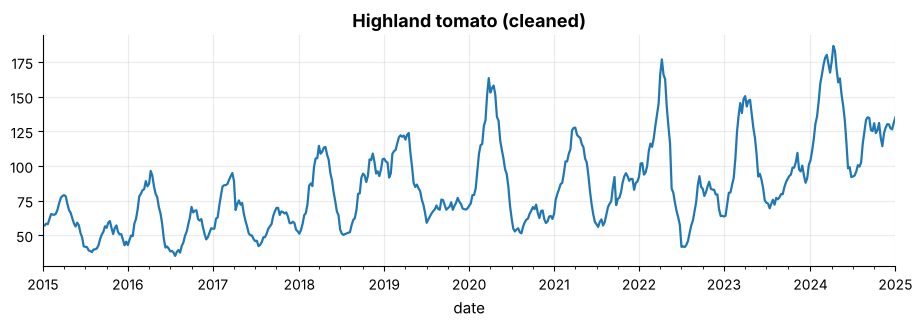

In [2]:
y = ag.price_series("tomato", "Highland", "W")
rain9 = ag.load_weather().set_index("date")["rainfall_mm"].resample("W").sum().reindex(y.index).rolling(9, min_periods=1).sum()
EXOG = pd.DataFrame({"rain_9w": rain9})
L, H = 52, 8                                     # look-back window and forecast horizon (weeks)
print(len(y), "weeks | window", L, "| horizon", H)
y.plot(figsize=(11, 3), title="Highland tomato (cleaned)"); plt.show()

## 1 · Turning a series into supervised sequences

For a forecast origin $t$ the **input** is the window of the last $L=52$ weeks, each week described by 4 features, and the **target** is the vector of $H=8$ cumulative log-changes:

| Feature (per week) | Why |
|---|---|
| weekly **log-return** | momentum / mean-reversion dynamics |
| `sin`, `cos` of day-of-year | the calendar position of that week |
| **9-week rainfall** (standardised) | the supply driver |

$$\text{target}_k=\log y_{t+k}-\log y_t,\qquad k=1,\dots,8$$

All scaling uses **training-period statistics only**. Time to build the pieces, inside one function that works from *any* training slice (so it can be called at every walk-forward origin).

---
### 🧩 Exercise 1: Leak-free scaling statistics  ⭐⭐

Write `fit_scalers(F_raw, Y_raw, train_rows, train_origins)` returning `(f_mu, f_sd, y_mu, y_sd)`:
- feature mean/std computed over rows `0 .. train_rows-1` only (`axis=0`);
- target mean/std computed over the target rows of `train_origins` (`Y_raw[train_origins]`).
Test it on the full series with `train_rows = 300` and origins `np.arange(52, 240)`; store the tuple in `scalers`.
Then show the leak: `leaky_f_mu` = feature means over **all** rows, and set `differs = not np.allclose(leaky_f_mu, scalers[0])`.

<details><summary>💡 Hint 1: gentle nudge</summary>

`F_raw[:train_rows].mean(axis=0)` and `.std(axis=0)`.

</details>

<details><summary>💡 Hint 2: bigger nudge</summary>

`Y_raw[train_origins].mean(axis=0)` and `.std(axis=0)`.

</details>

<details><summary>💡 Hint 3: almost the answer</summary>

`leaky_f_mu = F_raw.mean(axis=0)` uses weeks 300-522 (the future!): it *will* differ.

</details>

*Write your answer in the next cell, then run the check cell below it. Stuck after the hints? The full solution is in `solutions/`.*

In [ ]:
ly_ = np.log(y); doy_ = y.index.dayofyear.to_numpy()
F_raw = np.column_stack([ly_.diff().fillna(0).to_numpy(), np.sin(2 * np.pi * doy_ / 365.25), np.cos(2 * np.pi * doy_ / 365.25), rain9.to_numpy()])
Y_raw = np.column_stack([(ly_.shift(-k) - ly_).to_numpy() for k in range(1, H + 1)])

def fit_scalers(F_raw, Y_raw, train_rows, train_origins):
    return None

scalers = None
leaky_f_mu = None
differs = None

In [ ]:
try:
    ag.check("four arrays returned", scalers is not None and len(scalers) == 4)
    ag.check("feature mean uses only the first 300 rows", scalers is not None and np.allclose(scalers[0], F_raw[:300].mean(0)))
    ag.check("target scaling uses only the training origins", scalers is not None and np.allclose(scalers[3], Y_raw[np.arange(52, 240)].std(0)))
    ag.check("scaling with ALL the data would have given different (leaky) numbers", differs is True)
except Exception as _e:
    print('\u23f3 Not ready yet: finish the exercise cell above, then re-run this check.  (' + type(_e).__name__ + ': ' + str(_e)[:90] + ')')

---
### 🧩 Exercise 2: Define the LSTM forecaster  ⭐⭐

Define `LSTMForecaster(nn.Module)`: `nn.LSTM(4, 32, batch_first=True)` → take the **last time step's** hidden output → `nn.Dropout(0.1)` → `nn.Linear(32, 8)`.
Instantiate it as `lstm_net`, count parameters in `n_params`, and record the output shape for a random batch `(16, 52, 4)` in `out_shape`.

<details><summary>💡 Hint 1: gentle nudge</summary>

In `__init__`: `self.rnn = nn.LSTM(4, 32, batch_first=True)`; `self.drop = nn.Dropout(0.1)`; `self.head = nn.Linear(32, 8)`.

</details>

<details><summary>💡 Hint 2: bigger nudge</summary>

`forward`: `out, _ = self.rnn(x)`; `return self.head(self.drop(out[:, -1]))`.

</details>

<details><summary>💡 Hint 3: almost the answer</summary>

Parameters: LSTM 4·(32·36+64) = 4,864; Linear 32·8+8 = 264; total 5,128.

</details>

*Write your answer in the next cell, then run the check cell below it. Stuck after the hints? The full solution is in `solutions/`.*

In [ ]:
class LSTMForecaster(nn.Module):
    def __init__(self):
        super().__init__()
    def forward(self, x):
        return None

lstm_net = None
n_params = out_shape = None

In [ ]:
try:
    ag.check("5,128 parameters", n_params == 5128)
    ag.check("outputs 8 horizons per sample: (16, 8)", out_shape == (16, 8))
except Exception as _e:
    print('\u23f3 Not ready yet: finish the exercise cell above, then re-run this check.  (' + type(_e).__name__ + ': ' + str(_e)[:90] + ')')

## 2 · The forecaster that plugs into `walk_forward`

Everything below runs on a **training slice only**. Steps at each origin:

1. build features/targets from the slice; define origins that have a full window *and* a full 8-week target;
2. last **40 origins → validation**, with an **8-week embargo** before them; the rest → training;
3. scale with training statistics; train with **early stopping** on validation loss (AdamW, gradient clipping);
4. take the **last window**, predict 8 standardised log-changes, un-scale, convert to prices: $\hat y_{t+k}=y_t\,e^{\hat c_k}$.

In [7]:
class SeqForecaster(nn.Module):
    def __init__(self, kind="LSTM", n_feat=4, hidden=32, horizon=8, dropout=0.1):
        super().__init__()
        self.rnn = {"LSTM": nn.LSTM, "GRU": nn.GRU}[kind](n_feat, hidden, batch_first=True)
        self.head = nn.Sequential(nn.Dropout(dropout), nn.Linear(hidden, horizon))
    def forward(self, x):
        return self.head(self.rnn(x)[0][:, -1])

def make_forecaster(kind="LSTM", seed=0, epochs=60, patience=8, lr=2e-3, hidden=32):
    def fit_predict(train, h):
        n = len(train); ly = np.log(train); doy = train.index.dayofyear.to_numpy()
        F_raw = np.column_stack([ly.diff().fillna(0).to_numpy(), np.sin(2 * np.pi * doy / 365.25), np.cos(2 * np.pi * doy / 365.25), rain9.loc[train.index].to_numpy()])
        Y_raw = np.column_stack([(ly.shift(-k) - ly).to_numpy() for k in range(1, H + 1)])
        origins = np.arange(L, n - H)                                         # full window AND full target
        va_o = origins[-40:]; tr_o = origins[origins <= va_o[0] - H - 1]      # embargo between train and validation
        f_mu, f_sd = F_raw[:tr_o[-1] + 1].mean(0), F_raw[:tr_o[-1] + 1].std(0) + 1e-8
        y_mu, y_sd = Y_raw[tr_o].mean(0), Y_raw[tr_o].std(0) + 1e-8
        F, Y = (F_raw - f_mu) / f_sd, (np.nan_to_num(Y_raw) - y_mu) / y_sd
        win = lambda o: torch.tensor(np.stack([F[t - L + 1:t + 1] for t in o]), dtype=torch.float32)
        Xtr, Ytr, Xva, Yva = win(tr_o), torch.tensor(Y[tr_o], dtype=torch.float32), win(va_o), torch.tensor(Y[va_o], dtype=torch.float32)

        torch.manual_seed(seed)
        net = SeqForecaster(kind, hidden=hidden); opt = torch.optim.AdamW(net.parameters(), lr=lr, weight_decay=1e-3); lossf = nn.MSELoss()
        loader = DataLoader(TensorDataset(Xtr, Ytr), batch_size=32, shuffle=True)
        best, best_state, wait = np.inf, None, 0
        for ep in range(epochs):
            net.train()
            for xb, yb in loader:
                opt.zero_grad(); lossf(net(xb), yb).backward(); nn.utils.clip_grad_norm_(net.parameters(), 1.0); opt.step()
            net.eval()
            with torch.no_grad(): vl = lossf(net(Xva), Yva).item()
            if vl < best - 1e-4: best, best_state, wait = vl, {k: v.clone() for k, v in net.state_dict().items()}, 0
            else:
                wait += 1
                if wait >= patience: break
        net.load_state_dict(best_state); net.eval()
        with torch.no_grad():
            pred_std = net(torch.tensor(F[n - L:n][None], dtype=torch.float32))[0].numpy()    # window ending at the LAST observed week
        return float(train.iloc[-1]) * np.exp(pred_std * y_sd + y_mu)[:h]
    return fit_predict

t0 = time.time(); demo = make_forecaster()(y.iloc[:300], 8)
print("one forecast from the first origin (took %.1fs):" % (time.time() - t0), demo.round(1), "| last observed price:", round(float(y.iloc[299]), 1))

one forecast from the first origin (took 1.5s): [70.5 72.5 74.4 74.  74.1 73.5 71.2 69.2] | last observed price: 67.7


---
### 🧩 Exercise 3: From standardised output to a price  ⭐

The network outputs **standardised log-changes** `pred_std` (length 8). Write `to_prices(pred_std, last_price, y_mu, y_sd)` that un-scales them
(`change = pred_std * y_sd + y_mu`) and converts to prices (`last_price * exp(change)`). Test with `pred_std = np.zeros(8)`, `y_mu = np.full(8, 0.01)`,
`y_sd = np.full(8, 0.05)`, `last_price = 100` → store in `prices_test`. (Zero standardised output should give `100·e^0.01` at every horizon.)

<details><summary>💡 Hint 1: gentle nudge</summary>

Un-scale first: `change = pred_std * y_sd + y_mu`.

</details>

<details><summary>💡 Hint 2: bigger nudge</summary>

`last_price * np.exp(change)`: a log-change of 0.01 is about +1 %.

</details>

<details><summary>💡 Hint 3: almost the answer</summary>

Return a NumPy array of 8 prices.

</details>

*Write your answer in the next cell, then run the check cell below it. Stuck after the hints? The full solution is in `solutions/`.*

In [ ]:
def to_prices(pred_std, last_price, y_mu, y_sd):
    return None

prices_test = None

In [ ]:
try:
    ag.check("8 prices", prices_test is not None and len(prices_test) == 8)
    ag.check("zero standardised output = the mean historical change", prices_test is not None and np.allclose(prices_test, 100 * np.exp(0.01)))
    ag.check("prices scale linearly with last_price", np.allclose(to_prices(np.ones(8), 200.0, np.zeros(8), np.full(8, 0.1)), 2 * to_prices(np.ones(8), 100.0, np.zeros(8), np.full(8, 0.1))))
except Exception as _e:
    print('\u23f3 Not ready yet: finish the exercise cell above, then re-run this check.  (' + type(_e).__name__ + ': ' + str(_e)[:90] + ')')

## 3 · The benchmark run
27 origins × a fresh network each: about a minute or two on a laptop. We also recompute the cheap baselines and the **Ridge** model from Phase 7 under exactly the same protocol (same `walk_forward` call).

In [10]:
EVAL = dict(initial=300, horizon=8, step=8)
res = {}
res["naive"] = ag.walk_forward(y, ag.naive_forecast, **EVAL)
res["seasonal naive"] = ag.walk_forward(y, ag.seasonal_naive_forecast, **EVAL)
res["Ridge (Phase 7)"] = ag.walk_forward(y, ag.direct_ml_forecaster(lambda: make_pipeline(StandardScaler(), Ridge(10)), EXOG), **EVAL)
t0 = time.time()
res["LSTM"] = ag.walk_forward(y, make_forecaster("LSTM"), **EVAL)
print(f"LSTM walk-forward finished in {time.time() - t0:.0f}s over {res['LSTM'].origin_date.nunique()} origins")
board = ag.score_table(res, y_train=y.iloc[:300]); board

LSTM walk-forward finished in 14s over 27 origins


,MAE,RMSE,MAPE,MASE
Ridge (Phase 7),7.882,10.494,8.343,2.028
LSTM,10.328,13.930,10.746,2.658
naive,17.557,25.563,18.825,4.518
seasonal naive,19.482,23.572,19.240,5.013


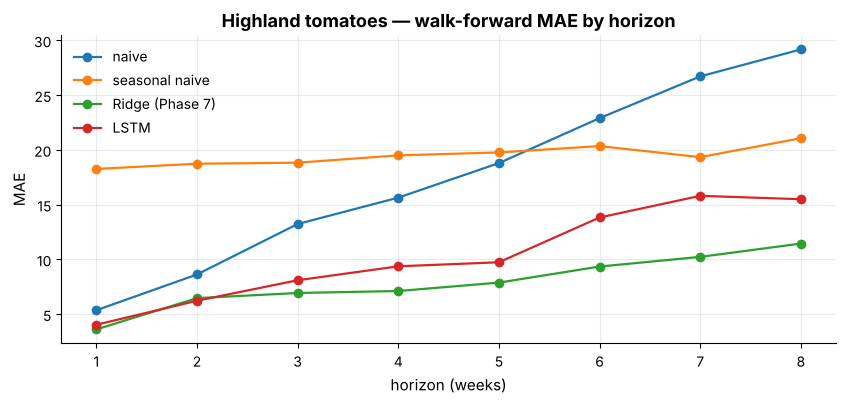

LSTM beats naive in 64% of individual forecasts; skill vs naive = 41%


In [11]:
by_h = pd.DataFrame({n: r.groupby("h").apply(lambda d: ag.mae(d.actual, d.forecast)) for n, r in res.items()})
ax = by_h.plot(marker="o", figsize=(10, 4)); ax.set(xlabel="horizon (weeks)", ylabel="MAE", title="Highland tomatoes: walk-forward MAE by horizon"); plt.show()
b, nv = res["LSTM"], res["naive"]
print(f"LSTM beats naive in {np.mean(np.abs(b.actual - b.forecast).to_numpy() < np.abs(nv.actual - nv.forecast).to_numpy()):.0%} of individual forecasts; skill vs naive = {1 - ag.mae(b.actual, b.forecast) / ag.mae(nv.actual, nv.forecast):.0%}")

### How to read this honestly

- Compare the LSTM row with **naive** (the floor) and **Ridge** (the Phase 7 champion). Where does the LSTM land?
- The evaluation has only **27 origins**, each with a single training run on ~190 samples. Differences of a few percent are **within noise**: one seed is one draw (Lesson 7.7 showed LSTM scores varying across seeds).
- A neural net with ~5,000 parameters trained on a few hundred windows is *data-starved*. That the LSTM clearly beats naive is genuine evidence it learned real structure, but **in our run Ridge is clearly better** (the LSTM's MAE is roughly a third higher). Lesson 8.3's small-data warning, confirmed on the real task.
- **Cost**: Ridge refits in milliseconds; the LSTM took minutes. If they tie on accuracy, the cheaper and more interpretable model wins.

## 4 · Forecast combination
Averaging forecasts from *different kinds* of models is a classic trick: their errors are partly independent, so the average is **never worse than the average of the two models' errors** (MAE is convex) and, when the models are comparably accurate, often beats *both*.
When one model is much better than the other, the combination typically lands **in between**: useful as a hedge, not as a free upgrade. Let's see which situation we're in.

---
### 🧩 Exercise 4: Combine the forecasts  ⭐⭐

`res["LSTM"]` and `res["Ridge (Phase 7)"]` list forecasts for exactly the same (origin, horizon) pairs in the same order.
Build `combo = res["LSTM"].copy()` with `combo["forecast"]` = the **simple average** of the two models' forecasts, and store:
`mae_combo`, `mae_lstm`, `mae_ridge` and `combo_beats_both = mae_combo < min(mae_lstm, mae_ridge)`.

<details><summary>💡 Hint 1: gentle nudge</summary>

`a, b = res['LSTM'], res['Ridge (Phase 7)']`: check `(a.target_date.values == b.target_date.values).all()` first.

</details>

<details><summary>💡 Hint 2: bigger nudge</summary>

`combo['forecast'] = (a.forecast.to_numpy() + b.forecast.to_numpy()) / 2`.

</details>

<details><summary>💡 Hint 3: almost the answer</summary>

`ag.mae(combo.actual, combo.forecast)` etc. Store the combo in `res['LSTM+Ridge']` to see it on the leaderboard.

</details>

*Write your answer in the next cell, then run the check cell below it. Stuck after the hints? The full solution is in `solutions/`.*

In [ ]:
combo = None
mae_combo = mae_lstm = mae_ridge = combo_beats_both = None

In [ ]:
try:
    ag.check("combo has the same rows as the LSTM results", combo is not None and len(combo) == len(res["LSTM"]))
    ag.check("combo forecast is the average", combo is not None and np.allclose(combo.forecast, (res["LSTM"].forecast + res["Ridge (Phase 7)"].forecast) / 2))
    ag.check("combo is better than the worse of the two models (as convexity guarantees)", mae_combo is not None and mae_combo < max(mae_lstm, mae_ridge))
except Exception as _e:
    print('\u23f3 Not ready yet: finish the exercise cell above, then re-run this check.  (' + type(_e).__name__ + ': ' + str(_e)[:90] + ')')

In [14]:
ag.score_table(res, y_train=y.iloc[:300])

,MAE,RMSE,MAPE,MASE
Ridge (Phase 7),7.882,10.494,8.343,2.028
LSTM+Ridge,8.338,11.009,8.685,2.146
LSTM,10.328,13.930,10.746,2.658
naive,17.557,25.563,18.825,4.518
seasonal naive,19.482,23.572,19.240,5.013


## 5 · Your write-up (do this as the final deliverable)

Fill this template: **numbers, not adjectives**:

1. **Question & protocol**: what, which series, how evaluated (one sentence).
2. **Result**: leaderboard (above) and the horizon plot; the LSTM's skill vs naive at h = 1, 4, 8.
3. **Verdict**: does the LSTM beat Ridge? By how much? Is that larger than the noise (try a second seed!)?
4. **Cost/complexity**: training time vs the linear model.
5. **Recommendation**: which model would you deploy, and what monitoring would you add?
6. **Limits**: synthetic data, 27 origins, single series, no shocks.

## 🏁 Extensions
1. **Seeds:** run `make_forecaster("LSTM", seed=s)` for 3 seeds and average the forecasts (an *ensemble*): does variance drop?
2. **GRU:** swap `kind="GRU"`. Fewer parameters, same accuracy?
3. **Features:** add the 4-week and 13-week momentum, the fuel index, or the `dev_52` mean-reversion signal as extra channels (`n_feat=…`).
4. **Pooling:** train one network on *all 12 market-crop series* (add a crop embedding): the setting where deep learning really starts to win.
5. **Transformer:** replace the LSTM with `TSTransformer` from Lesson 8.9.
6. **Uncertainty:** train with a *quantile (pinball) loss* for the 10th/50th/90th percentiles and check the coverage.

## 🎓 Mini-quiz
1. Why is the **embargo** between training and validation origins 8 weeks?
2. Why retrain the network at every walk-forward origin?
3. Two models tie on MAE. What else decides?

<details><summary>Answers</summary>

1. The targets look 8 weeks ahead, so training targets near the end of the training block would overlap the validation inputs. 2. In production you'd retrain as new data arrive; using one model trained once would make later origins unrealistically stale or leak earlier information. 3. Cost, speed, interpretability, robustness across seeds/horizons, ease of maintenance.
</details>

        ---
        ## 🧾 Recap
        - Neural forecasting recipe: **window → scale (train-only) → LSTM/GRU → multi-horizon head → early stopping → walk-forward retraining**.
- Benchmark under the **same protocol** as every other model; report skill vs naive, error by horizon, win-rate, and cost.
- On one short series the LSTM beats naive but is *not automatically* better than a good linear model; **ensembles and combinations** help.
- The honest answer to *'is deep learning better?'* is *'it depends on data volume, features and cost, and now you can measure it.'*

**Next up:** The Capstone: the Cooperative's Selling Advisor: forecasts with uncertainty turned into decisions.